# Bank Loan Analysis

## 1. Project Setup

### 1.1 Import Required Libraries

In [4]:
# Import pandas for data loading, manipulation, and analysis
import pandas as pd

# Import numpy for numerical calculations
import numpy as np

# Import matplotlib for creating static visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical and advanced visualizations
import seaborn as sns

# Import warnings to control unnecessary warning messages
import warnings

# Import Plotly Express for interactive visualizations
import plotly.express as px

# Ignore unnecessary warning messages during analysis
warnings.filterwarnings('ignore')


# Set a consistent Seaborn theme for project visualizations
sns.set_theme(style='whitegrid')

# Display a confirmation message
print("Everythings is ready!")

Everythings is ready!


## 2. Load Dataset

In this section, we will load the bank loan dataset from the Excel file
into a pandas DataFrame for further analysis.

In [132]:
# Define the path of the bank loan Excel dataset
file_path = (
    "C:/Users/rg747/Bank Analysis project "
    "BI+sql+python+excel+tableu/financial_loan_data_excel.xlsx"
)


# Load the Excel dataset into a pandas DataFrame
df = pd.read_excel(file_path)


# Display a confirmation message
print("✅ Bank loan dataset loaded successfully!")


# Display the number of rows and columns
print(f"📊 Dataset contains {df.shape[0]:,} rows and {df.shape[1]} columns.")

✅ Bank loan dataset loaded successfully!
📊 Dataset contains 38,576 rows and 24 columns.


### 2.1 Preview the Dataset

Display the first five rows of the dataset to understand the available columns and get an initial view of the loan records.

In [133]:
# Display the first five rows of the dataset
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [134]:
# Display the last five rows of the dataset
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,2021-07-11,2021-05-16,2021-05-16,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,2021-10-11,2021-04-16,2021-05-16,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,2021-09-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,2021-10-11,2021-05-16,2021-05-16,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,2021-07-11,2021-05-16,2021-05-16,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


In [135]:
# Select five random records from the dataset
df.sample(5)

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
32813,352130,NY,INDIVIDUAL,1 year,saint john's episcopal hospital,A,RENT,2021-07-08,2021-07-14,2021-04-09,...,A3,36 months,Not Verified,51000.0,0.1160,72.08,0.0800,5000,10,2412
8562,642822,PA,INDIVIDUAL,< 1 year,EQT,A,MORTGAGE,2021-01-11,2021-02-13,2021-01-13,...,A2,36 months,Not Verified,78000.0,0.0560,97.81,0.0579,3225,24,3485
26794,767012,TX,INDIVIDUAL,10+ years,Frisco Independent School District,B,MORTGAGE,2021-05-11,2021-09-13,2021-09-13,...,B3,36 months,Verified,68000.0,0.0026,261.88,0.1099,8000,12,9323
15774,634940,NY,INDIVIDUAL,10+ years,Performance Food Equipment Group,D,RENT,2021-12-10,2021-01-14,2021-01-14,...,D3,36 months,Source Verified,88000.0,0.1732,518.74,0.1483,15000,22,18676
13687,508655,PA,INDIVIDUAL,2 years,Bricmont,B,MORTGAGE,2021-04-10,2021-05-16,2021-07-12,...,B5,36 months,Source Verified,54000.0,0.2476,304.43,0.1136,9250,32,10777


In [136]:
# Count missing values in each column
df.isnull().sum()

id                          0
address_state               0
application_type            0
emp_length                  0
emp_title                1438
grade                       0
home_ownership              0
issue_date                  0
last_credit_pull_date       0
last_payment_date           0
loan_status                 0
next_payment_date           0
member_id                   0
purpose                     0
sub_grade                   0
term                        0
verification_status         0
annual_income               0
dti                         0
installment                 0
int_rate                    0
loan_amount                 0
total_acc                   0
total_payment               0
dtype: int64

### 2.2 Metadata of Data

Display the basic metadata of the dataset to understand its size and overall structure.

In [137]:
# Get the number of rows
print("Nos. of Rows:", df.shape[0])

Nos. of Rows: 38576


In [138]:
# Get the number of columns
print("Nos. of Rows:", df.shape[1])

Nos. of Rows: 24


In [139]:
# Display information about columns, data types, and non-null values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   id                     38576 non-null  int64         
 1   address_state          38576 non-null  str           
 2   application_type       38576 non-null  str           
 3   emp_length             38576 non-null  str           
 4   emp_title              37138 non-null  object        
 5   grade                  38576 non-null  str           
 6   home_ownership         38576 non-null  str           
 7   issue_date             38576 non-null  datetime64[us]
 8   last_credit_pull_date  38576 non-null  datetime64[us]
 9   last_payment_date      38576 non-null  datetime64[us]
 10  loan_status            38576 non-null  str           
 11  next_payment_date      38576 non-null  datetime64[us]
 12  member_id              38576 non-null  int64         
 13  purpose     

### 2.3 Data Types

Display the data types of each column to understand how the loan data is stored and identify columns that may require data type conversion.

In [140]:
# Get the data type of each column
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [141]:
# Generate descriptive statistics for numerical columns
df.describe().T

# .T has been added so that the columns appear vertically and the table remains readable.

,count,mean,min,25%,50%,75%,max,std
id,38576.0,681037.061385,54734.0,513517.0,662728.0,836506.0,1077501.0,211324.578218
issue_date,38576,2021-07-16 02:31:35.562007,2021-01-01 00:00:00,2021-04-11 00:00:00,2021-07-11 00:00:00,2021-10-11 00:00:00,2021-12-12 00:00:00,NaN
last_credit_pull_date,38576,2021-06-08 13:36:34.193280,2021-01-08 00:00:00,2021-04-15 00:00:00,2021-05-16 00:00:00,2021-08-13 00:00:00,2022-01-20 00:00:00,NaN
last_payment_date,38576,2021-06-26 09:52:08.909166,2021-01-08 00:00:00,2021-03-16 00:00:00,2021-06-14 00:00:00,2021-09-15 00:00:00,2021-12-15 00:00:00,NaN
next_payment_date,38576,2021-07-26 20:42:20.605557,2021-02-08 00:00:00,2021-04-16 00:00:00,2021-07-14 00:00:00,2021-10-15 00:00:00,2022-01-15 00:00:00,NaN
member_id,38576.0,847651.506299,70699.0,662978.75,847356.5,1045652.5,1314167.0,266810.45686
annual_income,38576.0,69644.54031,4000.0,41500.0,60000.0,83200.5,6000000.0,64293.681045
dti,38576.0,0.133274,0.0,0.0821,0.1342,0.1859,0.2999,0.066662
installment,38576.0,326.862965,15.69,168.45,283.045,434.4425,1305.19,209.092
int_rate,38576.0,0.120488,0.0542,0.0932,0.1186,0.1459,0.2459,0.037164


## 3. Key Performance Indicators (KPIs) Requirement

Identify the key performance indicators required to evaluate the overall performance of the bank loan portfolio.

### 3.1 Total Loan Application

Calculate the total number of loan applications available in the dataset to understand the overall volume of loan applications received by the bank.

In [142]:
# Count the total number of loan applications
total_loan_application = df['id'].count()


# Display the total loan applications
print(
    "Total Loan Applications:",
    total_loan_application
)

Total Loan Applications: 38576


### 3.1.1 MTD - Total Loan Application

Calculate the Month-to-Date (MTD) total number of loan applications based on the latest issue date available in the dataset. This KPI helps measure the number of loan applications received during the current month up to the latest available date.

In [143]:
# Convert issue_date column to datetime
df['issue_date'] = pd.to_datetime(df['issue_date'], errors='coerce')

# Find the latest loan issue date available in the dataset
latest_issue_date = df['issue_date'].max()

# Extract the year from the latest issue date
latest_year = latest_issue_date.year

# Extract the month from the latest issue date
latest_month = latest_issue_date.month

# Filter the dataset for the latest year and month
mtd_data = df[
    (df['issue_date'].dt.year == latest_year) &
    (df['issue_date'].dt.month == latest_month)
]

# Count the total loan applications for the latest month
mtd_loan_applications = mtd_data['id'].count()

# Display the MTD loan applications
print(
    f"MTD Loan Applications "
    f"(for {latest_issue_date.strftime('%B %Y')}): "
    f"{mtd_loan_applications}"
)

MTD Loan Applications (for December 2021): 4314


### 3.2 Total Funded Amount

Calculate the total funded amount across all loan applications to understand the overall amount of money funded by the bank through the loan portfolio.

In [144]:
# Calculate the total amount funded across all loan applications
total_funded_amount = df['loan_amount'].sum()


# Convert the total funded amount into millions
total_funded_amount_million = total_funded_amount / 1000000


# Display the total funded amount in millions
print(
    f"Total Funded Amount: "
    f"${total_funded_amount_million:.2f}M"
)

Total Funded Amount: $435.76M


#### 3.2.1 MTD - Total Funded Amount

Calculate the Month-to-Date (MTD) total funded amount based on the latest issue date available in the dataset. This KPI helps measure the total loan amount funded by the bank during the latest available month.

In [145]:
# Find the latest loan issue date available in the dataset
latest_issue_date = df['issue_date'].max()

# Extract the year from the latest issue date
latest_year = latest_issue_date.year

# Extract the month from the latest issue date
latest_month = latest_issue_date.month

# Filter the dataset for the latest year and month
mtd_data = df[
    (df['issue_date'].dt.year == latest_year) &
    (df['issue_date'].dt.month == latest_month)
]

# Calculate the total funded amount for the latest month
mtd_total_funded_amount = mtd_data['loan_amount'].sum()

# Convert the MTD funded amount into millions
mtd_total_funded_amount_millions = (
    mtd_total_funded_amount / 1000000
)

# Display the MTD total funded amount
print(
    "MTD Total Funded Amount "
    f"({latest_issue_date.strftime('%B %Y')}): "
    f"${mtd_total_funded_amount_millions:.2f}M"
)

MTD Total Funded Amount (December 2021): $53.98M


### 3.3 Total Amount Received

Calculate the total amount received from all loan payments recorded in the dataset. This KPI helps measure the overall amount collected by the bank from loan repayments.

In [146]:
# Calculate the total amount received from all loan payments
total_amount_received = df['total_payment'].sum()

# Convert the total amount received into millions
total_amount_received_millions = total_amount_received / 1000000

# Display the total amount received in millions
print(
    f"Total Amount Received: "
    f"${total_amount_received_millions:.2f}M"
)

Total Amount Received: $473.07M


#### 3.3.1 MTD - Total Amount Received

Calculate the Month-to-Date (MTD) total amount received based on the latest issue date available in the dataset. This KPI helps measure the total amount received from loan repayments during the latest available month.

In [147]:
# Find the latest loan issue date available in the dataset
latest_issue_date = df['issue_date'].max()

# Extract the year from the latest issue date
latest_year = latest_issue_date.year

# Extract the month from the latest issue date
latest_month = latest_issue_date.month

# Filter the dataset for the latest year and month
mtd_data = df[
    (df['issue_date'].dt.year == latest_year) &
    (df['issue_date'].dt.month == latest_month)
]

# Calculate the total amount received for the latest month
mtd_total_amount_received = mtd_data['total_payment'].sum()

# Convert the MTD amount received into millions
mtd_total_amount_received_millions = (
    mtd_total_amount_received / 1000000
)

# Display the MTD total amount received
print(
    "MTD Total Amount Received "
    f"({latest_issue_date.strftime('%B %Y')}): "
    f"${mtd_total_amount_received_millions:.2f}M"
)

MTD Total Amount Received (December 2021): $58.07M


### 3.4 Average Interest Rate

Calculate the average interest rate across all loan applications to understand the overall interest rate charged on the bank's loan portfolio.

In [148]:
# Calculate the average interest rate across all loan applications
average_interest_rate = df['int_rate'].mean() * 100

# Display the average interest rate
print("Average Interest Rate:{:.2f}%".format(average_interest_rate))

Average Interest Rate:12.05%


### 3.5 Average Debt To Income Ratio

Calculate the average debt-to-income ratio across all loan applications to understand the average level of debt relative to the income of borrowers.

In [149]:
# Calculate the average debt to income ratio
average_dti = df['dti'].mean()*100

# Display the average debt to income ratio
print("Average Debt To Income Ratio: {:.2f}%".format(average_dti))

Average Debt To Income Ratio: 13.33%


### 3.6 Good Loan Metrics

Calculate key metrics for good loans, including the number of good loan applications, funded amount, total amount received, and the percentage of good loan applications. Good loans are defined as loans with a status of "Fully Paid" or "Current".

In [150]:
# Filter loans with Fully Paid and Current status as good loans
good_loans = df[df['loan_status'].isin(["Fully Paid", "Current"])]

# Calculate the total number of loan applications
total_loan_applications = df['id'].count()

# Calculate the number of good loan applications
good_loan_applications = good_loans['id'].count()

# Calculate the total funded amount for good loans
good_loan_funded_amount = good_loans['loan_amount'].sum()

# Calculate the total amount received for good loans
good_loan_received = good_loans['total_payment'].sum()

# Convert the good loan funded amount into millions
good_loan_funded_amount_millions = good_loan_funded_amount / 1_000_000

# Convert the good loan received amount into millions
good_loan_received_millions = good_loan_received / 1_000_000

# Calculate the percentage of good loan applications
good_loan_percentage = (
    good_loan_applications / total_loan_applications
) * 100

# Display the number of good loan applications
print(
    "Good Loan Applications:",
    good_loan_applications
)

# Display the good loan funded amount in millions
print(
    "Good Loan Funded Amount (in Millions): "
    "${:.2f}M".format(good_loan_funded_amount_millions)
)

# Display the good loan total received amount in millions
print(
    "Good Loan Total Received (in Millions): "
    "${:.2f}M".format(good_loan_received_millions)
)

# Display the percentage of good loan applications
print(
    "Percentage of Good Loan Applications: "
    "{:.2f}%".format(good_loan_percentage)
)

Good Loan Applications: 33243
Good Loan Funded Amount (in Millions): $370.22M
Good Loan Total Received (in Millions): $435.79M
Percentage of Good Loan Applications: 86.18%


### 3.7 Bad Loan Metrics

Calculate key metrics for bad loans, including the number of bad loan applications, funded amount, total amount received, and the percentage of bad loan applications. Bad loans are defined as loans with a status of "Charged Off".

In [151]:
# Filter loans with Charged Off status as bad loans
bad_loans = df[df['loan_status'].isin(["Charged Off"])]

# Calculate the total number of loan applications
total_loan_applications = df['id'].count()

# Calculate the number of bad loan applications
bad_loan_applications = bad_loans['id'].count()

# Calculate the total funded amount for bad loans
bad_loan_funded_amount = bad_loans['loan_amount'].sum()

# Calculate the total amount received for bad loans
bad_loan_received = bad_loans['total_payment'].sum()

# Convert the bad loan funded amount into millions
bad_loan_funded_amount_millions = bad_loan_funded_amount / 1_000_000

# Convert the bad loan received amount into millions
bad_loan_received_millions = bad_loan_received / 1_000_000

# Calculate the percentage of bad loan applications
bad_loan_percentage = (
    bad_loan_applications / total_loan_applications
) * 100

# Display the number of bad loan applications
print(
    "Bad Loan Applications:",
    bad_loan_applications
)

# Display the bad loan funded amount in millions
print(
    "Bad Loan Funded Amount (in Millions): "
    "${:.2f}M".format(bad_loan_funded_amount_millions)
)

# Display the bad loan total received amount in millions
print(
    "Bad Loan Total Received (in Millions): "
    "${:.2f}M".format(bad_loan_received_millions)
)

# Display the percentage of bad loan applications
print(
    "Percentage of Bad Loan Applications: "
    "{:.2f}%".format(bad_loan_percentage)
)

Bad Loan Applications: 5333
Bad Loan Funded Amount (in Millions): $65.53M
Bad Loan Total Received (in Millions): $37.28M
Percentage of Bad Loan Applications: 13.82%


## 4. Visualizations

Create business-focused visualizations to analyze loan portfolio performance, funding trends, borrower characteristics, and other key patterns identified during the analysis.

The visualizations will transform the calculated metrics and analytical results into clear, easy-to-understand charts that can support business insights and decision-making.

Each visualization will use an appropriate chart type, meaningful titles, data labels where required, and a consistent professional theme to maintain a clean and presentation-ready dashboard style.

### 4.1 Monthly Trends by Issue Date for Total Funded Amount

Analyze the monthly trend of the total funded loan amount based on the loan issue date. This visualization helps identify how the bank's loan funding volume changes across different months.

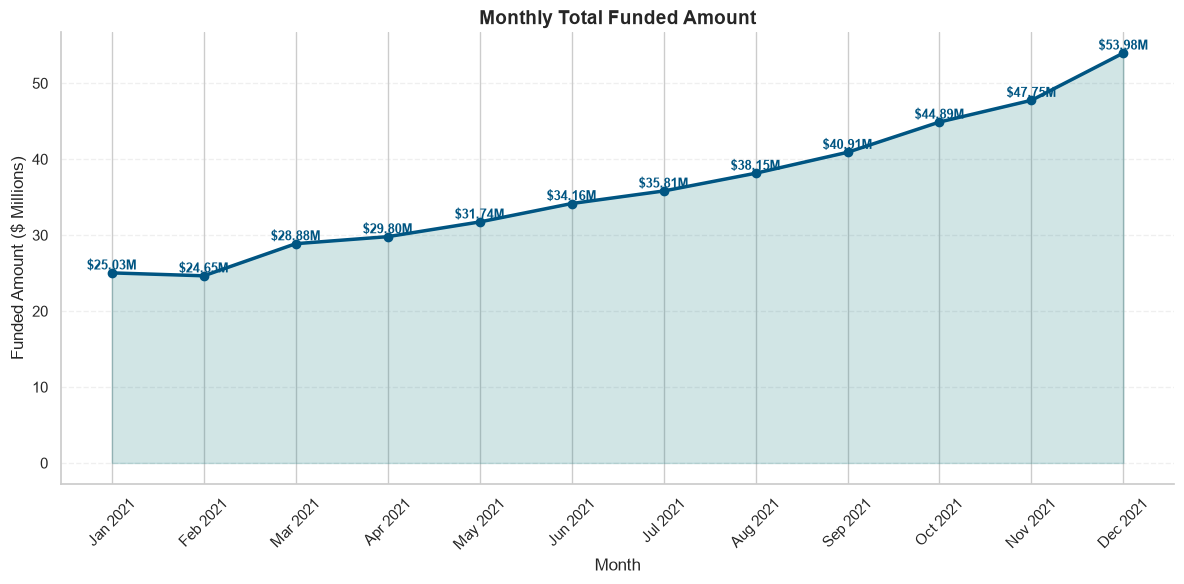

In [169]:
# Sort the dataset by loan issue date
monthly_funded = (
    df
    .sort_values('issue_date')
    
    # Create a month-year column from the issue date
    .assign(
        month_name=lambda x: x['issue_date'].dt.strftime('%b %Y')
    )
    
    # Calculate total funded amount for each month
    .groupby('month_name', sort=False)['loan_amount']
    .sum()
    
    # Convert the funded amount into millions
    .div(1_000_000)
    
    # Convert the result back into a DataFrame
    .reset_index(name='loan_amount_millions')
)

# ---------------------------------------------------------
# Define the project visualization theme
# ---------------------------------------------------------

# Define the primary deep blue color
PRIMARY_BLUE = '#005582'

# Define the secondary teal color
SECONDARY_TEAL = '#006F74'

# ---------------------------------------------------------
# Create the monthly funded amount visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(12, 6))

# Create a filled area below the monthly trend line
plt.fill_between(
    range(len(monthly_funded)),
    monthly_funded['loan_amount_millions'],
    color=SECONDARY_TEAL,
    alpha=0.18
)

# Create the monthly funded amount trend line
plt.plot(
    range(len(monthly_funded)),
    monthly_funded['loan_amount_millions'],
    color=PRIMARY_BLUE,
    linewidth=2.5,
    marker='o',
    markersize=6
)

# ---------------------------------------------------------
# Add data labels
# ---------------------------------------------------------

# Add the funded amount value above each month
for i, row in monthly_funded.iterrows():
    
    plt.text(
        i,
        row['loan_amount_millions'] + 0.1,
        f"${row['loan_amount_millions']:.2f}M",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=PRIMARY_BLUE
    )

# ---------------------------------------------------------
# Format the chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Monthly Total Funded Amount',
    fontsize=14,
    fontweight='bold'
)

# Set the X-axis label
plt.xlabel('Month')

# Set the Y-axis label
plt.ylabel('Funded Amount ($ Millions)')

# Display month names on the X-axis
plt.xticks(
    ticks=range(len(monthly_funded)),
    labels=monthly_funded['month_name'],
    rotation=45
)

# Add light horizontal grid lines
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Adjust chart spacing
plt.tight_layout()

# Display the visualization
plt.show()

### 4.2 Monthly Trends by Issue Date for Total Amount Received

Analyze the monthly trend of the total amount received from loan payments based on the loan issue date. This visualization helps track how the amount received changes across different months and provides a view of the bank's monthly repayment inflow.


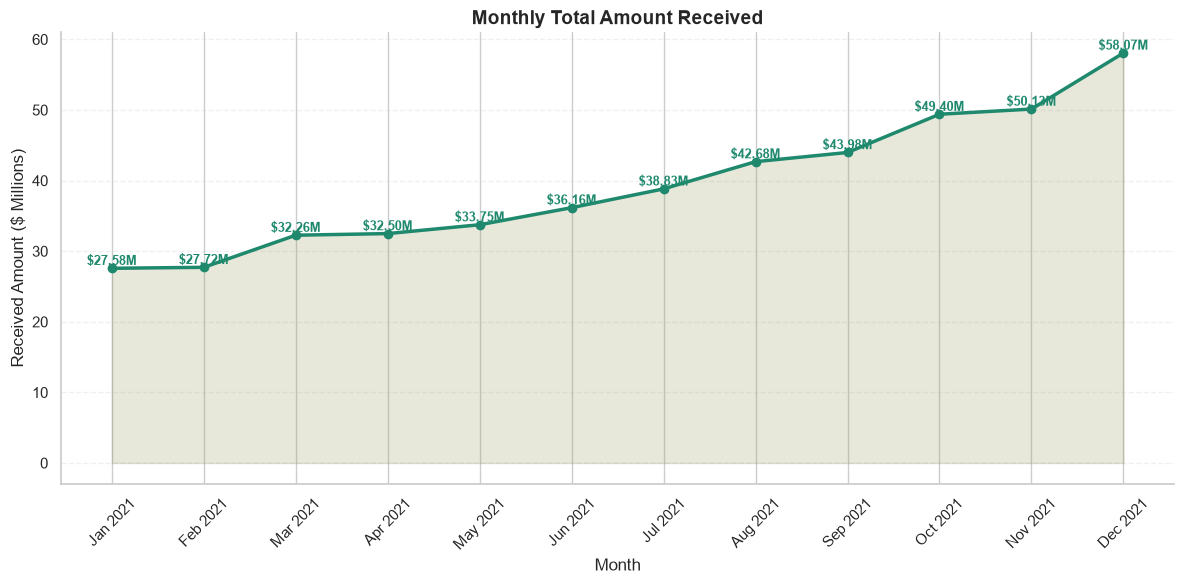

In [170]:
# Sort the dataset by loan issue date
monthly_received = (
    df
    .sort_values('issue_date')
    
    # Create a month-year column from the issue date
    .assign(
        month_name=lambda x: x['issue_date'].dt.strftime('%b %Y')
    )
    
    # Calculate total amount received for each month
    .groupby('month_name', sort=False)['total_payment']
    .sum()
    
    # Convert the received amount into millions
    .div(1_000_000)
    
    # Convert the result back into a DataFrame
    .reset_index(name='received_amount_millions')
)

# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define the primary green-teal color
PRIMARY_GREEN = '#1F896E'

# Define the light olive fill color
LIGHT_OLIVE = '#A0A06F'

# ---------------------------------------------------------
# Create the monthly received amount visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(12, 6))

# Create a filled area below the monthly trend line
plt.fill_between(
    range(len(monthly_received)),
    monthly_received['received_amount_millions'],
    color=LIGHT_OLIVE,
    alpha=0.25
)

# Create the monthly received amount trend line
plt.plot(
    range(len(monthly_received)),
    monthly_received['received_amount_millions'],
    color=PRIMARY_GREEN,
    linewidth=2.5,
    marker='o',
    markersize=6
)

# ---------------------------------------------------------
# Add data labels
# ---------------------------------------------------------

# Add the received amount value above each month
for i, row in monthly_received.iterrows():
    
    plt.text(
        i,
        row['received_amount_millions'] + 0.1,
        f"${row['received_amount_millions']:.2f}M",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=PRIMARY_GREEN
    )

# ---------------------------------------------------------
# Format the chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Monthly Total Amount Received',
    fontsize=14,
    fontweight='bold'
)

# Set the X-axis label
plt.xlabel('Month')

# Set the Y-axis label
plt.ylabel('Received Amount ($ Millions)')

# Display month names on the X-axis
plt.xticks(
    ticks=range(len(monthly_received)),
    labels=monthly_received['month_name'],
    rotation=45
)

# Add light horizontal grid lines
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# Remove unnecessary top and right borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Adjust chart spacing
plt.tight_layout()

# Display the visualization
plt.show()

### 4.3 Monthly Trends by Issue Date for Total Loan Applications

Analyze the monthly trend of total loan applications based on the loan issue date to understand application volume patterns and identify periods of higher or lower loan demand.

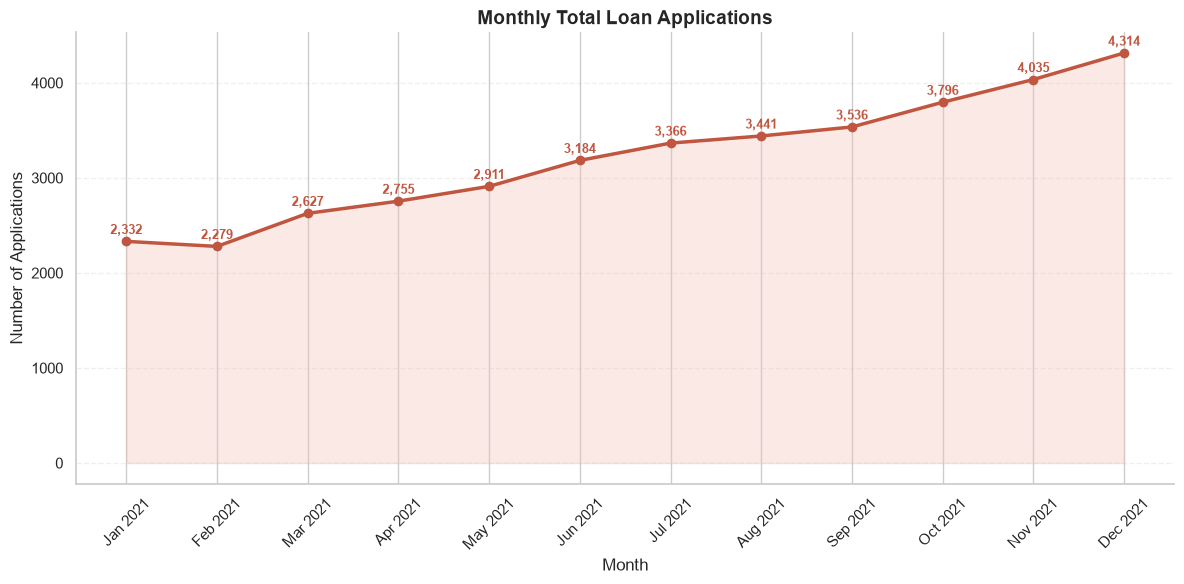

In [171]:
# Sort the dataset by loan issue date
monthly_applications = (
    df
    .sort_values('issue_date')
    
    # Create a month-year column from the issue date
    .assign(
        month_name=lambda x: x['issue_date'].dt.strftime('%b %Y')
    )
    
    # Calculate total loan applications for each month
    .groupby('month_name', sort=False)['id']
    .count()
    
    # Convert the result back into a DataFrame
    .reset_index(name='loan_applications_count')
)

# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define the primary terracotta color
PRIMARY_TERRACOTTA = '#C05640'

# Define the light peach fill color
LIGHT_PEACH = '#F2C1B6'

# ---------------------------------------------------------
# Create the monthly loan applications visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(12, 6))


# Create a filled area below the monthly trend line
plt.fill_between(
    range(len(monthly_applications)),
    monthly_applications['loan_applications_count'],
    color=LIGHT_PEACH,
    alpha=0.35
)

# Create the monthly loan applications trend line
plt.plot(
    range(len(monthly_applications)),
    monthly_applications['loan_applications_count'],
    color=PRIMARY_TERRACOTTA,
    linewidth=2.5,
    marker='o',
    markersize=6
)

# ---------------------------------------------------------
# Add data labels
# ---------------------------------------------------------

# Add the application count above each month
for i, row in monthly_applications.iterrows():
    
    plt.text(
        i,
        row['loan_applications_count'] + 50,
        f"{row['loan_applications_count']:,}",
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
        color=PRIMARY_TERRACOTTA
    )

# ---------------------------------------------------------
# Format the chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Monthly Total Loan Applications',
    fontsize=14,
    fontweight='bold'
)

# Set the X-axis label
plt.xlabel('Month')

# Set the Y-axis label
plt.ylabel('Number of Applications')

# Display month names on the X-axis
plt.xticks(
    ticks=range(len(monthly_applications)),
    labels=monthly_applications['month_name'],
    rotation=45
)

# Add light horizontal grid lines
plt.grid(
    axis='y',
    linestyle='--',
    alpha=0.3
)

# Remove unnecessary top and right borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Adjust chart spacing
plt.tight_layout()

# Display the visualization
plt.show()

#### 4.3.1 Create State Name Column

Create a new State Name column by converting state abbreviations from the address_state column into readable state names for reporting and visualization.

In [172]:
# Create a mapping dictionary for state abbreviations
state_name_mapping = {
    "AK": "Alaska",
    "AL": "Alabama",
    "AR": "Arkansas",
    "AZ": "Arizona",
    "CA": "California",
    "CO": "Colorado",
    "CT": "Connecticut",
    "DC": "D.C.",
    "DE": "Delaware",
    "FL": "Florida",
    "GA": "Georgia",
    "HI": "Hawaii",
    "IA": "Iowa",
    "ID": "Idaho",
    "IL": "Illinois",
    "IN": "Indiana",
    "KS": "Kansas",
    "KY": "Kentucky",
    "LA": "Louisiana",
    "MA": "Massachusetts",
    "MD": "Maryland",
    "ME": "Maine",
    "MI": "Michigan",
    "MN": "Minnesota",
    "MO": "Missouri",
    "MS": "Mississippi",
    "MT": "Montana",
    "NC": "N. Carolina",
    "ND": "N. Dakota",
    "NE": "Nebraska",
    "NH": "N. Hampshire",
    "NJ": "New Jersey",
    "NM": "N. Mexico",
    "NV": "Nevada",
    "NY": "New York",
    "OH": "Ohio",
    "OK": "Oklahoma",
    "OR": "Oregon",
    "PA": "Pennsylvania",
    "RI": "Rhode Island",
    "SC": "S. Carolina",
    "SD": "S. Dakota",
    "TN": "Tennessee",
    "TX": "Texas",
    "UT": "Utah",
    "VA": "Virginia",
    "VT": "Vermont",
    "WA": "Washington",
    "WI": "Wisconsin",
    "WV": "W. Virginia",
    "WY": "Wyoming"
}


# Create a new State Name column
df['State Name'] = (
    df['address_state']
    .map(state_name_mapping)
    .fillna('Other')
)


# Display the original and new state columns
print("✅ State Name column created successfully!")

display(
    df[['address_state', 'State Name']]
    .drop_duplicates()
    .sort_values('address_state')
)

✅ State Name column created successfully!


,address_state,State Name
1523,AK,Alaska
237,AL,Alabama
92,AR,Arkansas
51,AZ,Arizona
1,CA,California
63,CO,Colorado
56,CT,Connecticut
352,DC,D.C.
80,DE,Delaware
8,FL,Florida


#### 4.3.2 Create Purpose Name Column

Create a new Purpose Name column by converting the purpose values into standardized and readable names for reporting and visualization.

In [158]:
# Create a mapping dictionary for loan purposes
purpose_name_mapping = {
    "car": "Car",
    "credit card": "Credit Card",
    "Debt consolidation": "Debt Consolidation",
    "educational": "Education",
    "home improvement": "Home Improvement",
    "house": "House Purchase",
    "major purchase": "Major Purchase",
    "medical": "Medical",
    "moving": "Moving",
    "other": "Other",
    "renewable_energy": "Renewable Energy",
    "small business": "Small Business",
    "vacation": "Vacation",
    "wedding": "Wedding"
}


# Create a new Purpose Name column
df['Purpose Name'] = (
    df['purpose']
    .map(purpose_name_mapping)
    .fillna('Other')
)


# Display the original and new purpose columns
print("✅ Purpose Name column created successfully!")

display(
    df[['purpose', 'Purpose Name']]
    .drop_duplicates()
    .sort_values('purpose')
)

✅ Purpose Name column created successfully!


,purpose,Purpose Name
6495,Debt consolidation,Debt Consolidation
0,car,Car
1497,credit card,Credit Card
24709,educational,Education
25024,home improvement,Home Improvement
27900,house,House Purchase
28266,major purchase,Major Purchase
30376,medical,Medical
31043,moving,Moving
31602,other,Other


### 4.4 Regional Analysis by State for Total Funded Amount

Analyze the total funded loan amount across different states to understand regional funding distribution and identify states with higher or lower loan funding.

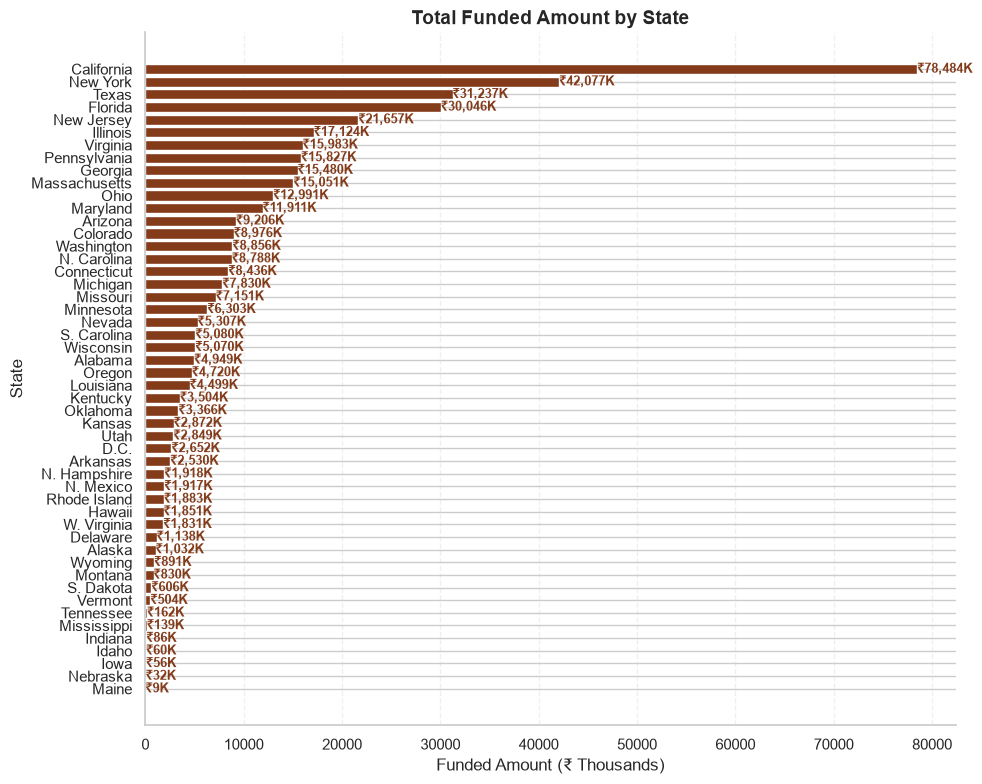

In [157]:
# Group the data by state and calculate total funded amount
state_funding = (
    df
    .groupby('State Name')['loan_amount']
    .sum()
    .sort_values(ascending=True)
)

# Convert the funded amount into thousands
state_funding_thousands = state_funding / 1000

# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define the primary brown color
PRIMARY_BROWN = '#833B1A'

# Define the light beige fill color
LIGHT_BEIGE = '#D9B99B'

# ---------------------------------------------------------
# Create the state-wise funded amount visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(10, 8))

# Create the horizontal bar chart
bars = plt.barh(
    state_funding_thousands.index,
    state_funding_thousands.values,
    color=PRIMARY_BROWN
)

# ---------------------------------------------------------
# Add data labels
# ---------------------------------------------------------

# Add funded amount value at the end of each bar
for bar in bars:
    
    width = bar.get_width()
    
    plt.text(
        width + 10,
        bar.get_y() + bar.get_height() / 2,
        f'₹{width:,.0f}K',
        va='center',
        fontsize=9,
        fontweight='bold',
        color=PRIMARY_BROWN
    )

# ---------------------------------------------------------
# Format the chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Total Funded Amount by State',
    fontsize=14,
    fontweight='bold'
)

# Set the X-axis label
plt.xlabel('Funded Amount (₹ Thousands)')

# Set the Y-axis label
plt.ylabel('State')

# Add light vertical grid lines
plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)

# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

# Adjust chart spacing
plt.tight_layout()

# Display the visualization
plt.show()

### 4.5 Loan Term Analysis by Total Funded Amount

Analyze the total funded loan amount across different loan terms to understand how the funded portfolio is distributed by repayment period.

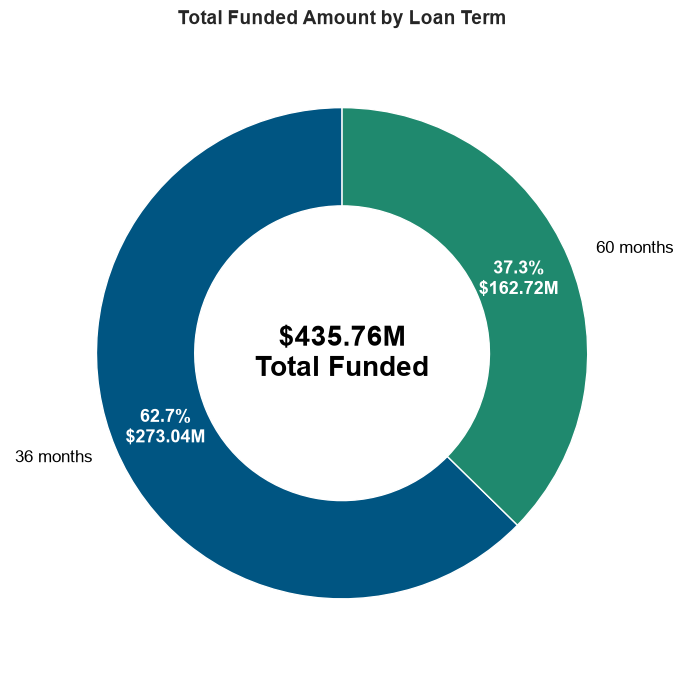

In [173]:
# Calculate total funded amount for each loan term
term_funding_millions = (
    df
    .groupby('term')['loan_amount']
    .sum()
    / 1_000_000
)


# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define colors for different loan terms
TERM_COLORS = [
    '#005582',
    '#1F896E',
    '#FFB279'
]


# ---------------------------------------------------------
# Create the Loan Term Donut Chart
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(7, 7))


# Create the donut chart
wedges, texts, autotexts = plt.pie(
    term_funding_millions,
    labels=term_funding_millions.index,
    colors=TERM_COLORS[:len(term_funding_millions)],

    # Display percentage and funded amount
    autopct=lambda p: (
        f"{p:.1f}%\n"
        f"${p * term_funding_millions.sum() / 100:.2f}M"
    ),

    # Position the percentage labels inside the donut ring
    pctdistance=0.78,

    # Start the donut from the top
    startangle=90,

    # Create the donut hole
    wedgeprops={'width': 0.40}
)


# ---------------------------------------------------------
# Format the Data Labels
# ---------------------------------------------------------

# Make percentage and funded amount labels white
for autotext in autotexts:

    autotext.set_color('white')

    autotext.set_fontsize(13)

    autotext.set_fontweight('bold')


# ---------------------------------------------------------
# Format the Term Labels
# ---------------------------------------------------------

# Keep the loan term labels outside the donut
for text in texts:

    text.set_color('black')

    text.set_fontsize(12)


# ---------------------------------------------------------
# Add Total Funded Amount in the Center
# ---------------------------------------------------------

# Calculate total funded amount
total_funded = term_funding_millions.sum()


# Display total funded amount in the donut center
plt.text(
    0,
    0,
    f"${total_funded:.2f}M\nTotal Funded",
    ha='center',
    va='center',
    fontsize=20,
    fontweight='bold',
    color='black'
)


# ---------------------------------------------------------
# Format the Chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Total Funded Amount by Loan Term',
    fontsize=14,
    fontweight='bold'
)


# Keep the donut perfectly circular
plt.axis('equal')


# Adjust chart spacing
plt.tight_layout()


# Display the visualization
plt.show()

### 4.6 Employee Length Analysis by Total Funded Amount

Analyze the total funded loan amount across different employment length categories to understand how the loan portfolio is distributed based on borrowers' employment experience.

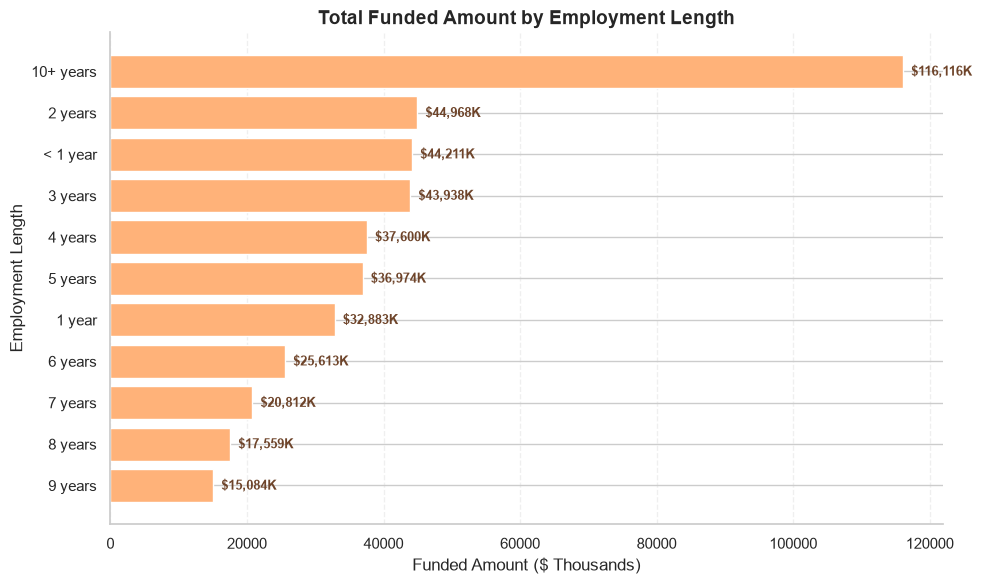

In [168]:
# Calculate total funded amount for each employment length
emp_funding = (
    df
    .groupby('emp_length')['loan_amount']
    .sum()
    .sort_values()
)


# Convert the funded amount into thousands
emp_funding_thousands = emp_funding / 1_000


# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define the primary amber color
PRIMARY_AMBER = '#FFB279'

# Define the secondary brown color
SECONDARY_BROWN = '#6E442A'


# ---------------------------------------------------------
# Create the Employee Length Visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(10, 6))


# Create the horizontal bar chart
bars = plt.barh(
    emp_funding_thousands.index,
    emp_funding_thousands.values,
    color=PRIMARY_AMBER
)


# ---------------------------------------------------------
# Add Data Labels
# ---------------------------------------------------------

# Display funded amount at the end of each bar
for bar in bars:

    # Get the width of the current bar
    width = bar.get_width()

    # Add the funded amount label
    plt.text(
        width + (emp_funding_thousands.max() * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.0f}K",
        va='center',
        fontsize=9,
        fontweight='bold',
        color=SECONDARY_BROWN
    )


# ---------------------------------------------------------
# Format the Chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Total Funded Amount by Employment Length',
    fontsize=14,
    fontweight='bold'
)


# Set the X-axis label
plt.xlabel('Funded Amount ($ Thousands)')


# Set the Y-axis label
plt.ylabel('Employment Length')


# Add light vertical grid lines
plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)


# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)


# Adjust chart spacing
plt.tight_layout()


# Display the visualization
plt.show()

### 4.4 Loan Purpose Analysis by Total Funded Amount

Analyze the total funded loan amount across different loan purposes to understand which purposes receive the highest share of the bank's funded loan portfolio.

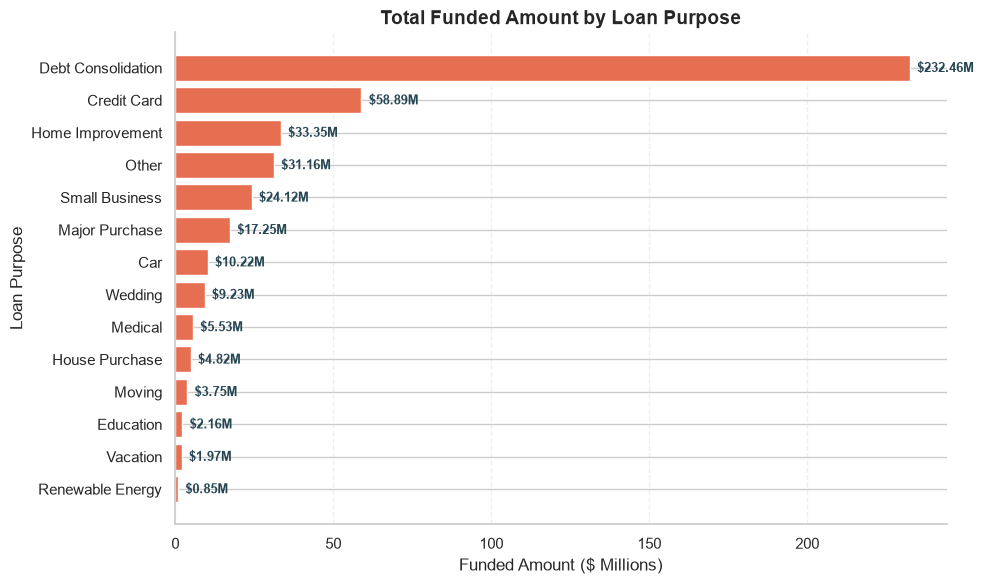

In [178]:
# Calculate total funded amount for each loan purpose
purpose_funding_millions = (
    df
    .groupby('Purpose Name')['loan_amount']
    .sum()
    .sort_values()
    / 1_000_000
)


# ---------------------------------------------------------
# Define the visualization theme
# ---------------------------------------------------------

# Define the primary coral color
PRIMARY_CORAL = '#E76F51'

# Define the label color
LABEL_COLOR = '#264653'


# ---------------------------------------------------------
# Create the Loan Purpose Visualization
# ---------------------------------------------------------

# Create the figure
plt.figure(figsize=(10, 6))


# Create the horizontal bar chart
bars = plt.barh(
    purpose_funding_millions.index,
    purpose_funding_millions.values,
    color=PRIMARY_CORAL
)


# ---------------------------------------------------------
# Add Data Labels
# ---------------------------------------------------------

# Display funded amount at the end of each bar
for bar in bars:

    # Get the width of the current bar
    width = bar.get_width()

    # Add the funded amount label
    plt.text(
        width + (purpose_funding_millions.max() * 0.01),
        bar.get_y() + bar.get_height() / 2,
        f"${width:,.2f}M",
        va='center',
        fontsize=9,
        fontweight='bold',
        color=LABEL_COLOR
    )


# ---------------------------------------------------------
# Format the Chart
# ---------------------------------------------------------

# Set the chart title
plt.title(
    'Total Funded Amount by Loan Purpose',
    fontsize=14,
    fontweight='bold'
)


# Set the X-axis label
plt.xlabel('Funded Amount ($ Millions)')


# Set the Y-axis label
plt.ylabel('Loan Purpose')


# Add light vertical grid lines
plt.grid(
    axis='x',
    linestyle='--',
    alpha=0.3
)


# Remove unnecessary borders
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)


# Adjust chart spacing
plt.tight_layout()


# Display the visualization
plt.show()

### 4.5 Home Ownership Analysis by Total Funded Amount

Analyze the total funded loan amount across different home ownership categories to understand how the bank's funded loan portfolio is distributed among borrowers based on their home ownership status.

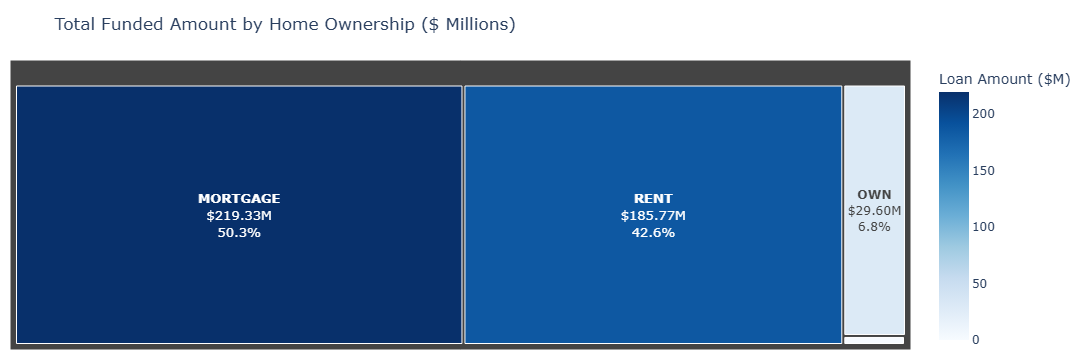

In [185]:
# Calculate the total funded amount for each home ownership category
home_funding = (
    df
    .groupby('home_ownership')['loan_amount']
    .sum()
    .reset_index()
)

# ---------------------------------------------------------
# Convert Funded Amount into Millions
# ---------------------------------------------------------

# Convert the total funded amount from dollars into millions
home_funding['loan_amount_millions'] = (
    home_funding['loan_amount'] / 1_000_000
)

# ---------------------------------------------------------
# Create the Home Ownership Treemap
# ---------------------------------------------------------

# Create the interactive treemap
fig = px.treemap(
    home_funding,

    # Use home ownership as the treemap category
    path=['home_ownership'],

    # Use funded amount to control box size
    values='loan_amount_millions',

    # Use funded amount to control color intensity
    color='loan_amount_millions',

    # Use a blue gradient similar to the reference chart
    color_continuous_scale='Blues',

    # Set the chart title
    title='Total Funded Amount by Home Ownership ($ Millions)'
)

# ---------------------------------------------------------
# Format Treemap Labels
# ---------------------------------------------------------

# Display category name, funded amount and percentage
fig.update_traces(
    texttemplate=(
        '<b>%{label}</b><br>'
        '$%{value:.2f}M<br>'
        '%{percentRoot:.1%}'
    ),

    # Keep labels inside the treemap boxes
    textposition='middle center',

    # Set label font size
    textfont=dict(
        size=13
    )
)

# ---------------------------------------------------------
# Format the Color Scale
# ---------------------------------------------------------

# Keep the blue color scale visible on the right
fig.update_coloraxes(
    colorbar=dict(
        title='Loan Amount ($M)'
    )
)

# ---------------------------------------------------------
# Format the Chart Layout
# ---------------------------------------------------------

# Remove unnecessary margins
fig.update_layout(
    margin=dict(
        l=10,
        r=10,
        t=60,
        b=10
    )
)

# ---------------------------------------------------------
# Display the Visualization
# ---------------------------------------------------------

# Display the interactive treemap
fig.show()